# Preparing the repair study
## Calibration, session matching, and the path to held-out evaluation

This notebook summarizes the latest setup for the **weight-repair** study. It compares the deliberately weakened calibration model with its reference, shows what has been prepared for the two reviewers, and explains how a future main cohort will be planned, frozen, and scored.

**Operator-facing material:** this notebook reveals the constructed calibration weakness and development diagnostics. Do not send it, the reference checkpoints, private session mappings, or validation labels to a blinded reviewer. Send only the appropriate rendered prompt and permitted probe feedback.

In [1]:
from pathlib import Path
import hashlib, json, sys
import numpy as np
import torch
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

ROOT = Path.cwd().resolve()
if not (ROOT / 'experiment.json').exists():
    ROOT = ROOT.parent
if not (ROOT / 'experiment.json').exists():
    raise FileNotFoundError('Open this notebook from the project root or notebooks/ directory.')
sys.path.insert(0, str(ROOT / 'src'))
from weight_reader.data import make_split
from weight_reader.editing import validation_metrics
from weight_reader.model import WeightReaderMLP

config = json.loads((ROOT / 'experiment.json').read_text())
OUT = ROOT / 'results' / 'figures'
OUT.mkdir(parents=True, exist_ok=True)
torch.set_num_threads(1)
plt.rcParams.update({'figure.dpi':110, 'savefig.dpi':300, 'font.size':11,
                     'axes.spines.top':False, 'axes.spines.right':False,
                     'axes.titleweight':'bold', 'figure.facecolor':'white'})
def save_figure(fig,name):
    fig.savefig(OUT / f'{name}.png',bbox_inches='tight',facecolor='white')
    fig.savefig(OUT / f'{name}.svg',bbox_inches='tight',facecolor='white')
def load_model(name):
    path = ROOT / 'checkpoints' / name
    if not path.is_file():
        raise FileNotFoundError(f'Missing {path}. Recreate the local calibration checkpoint using the instructions in README.')
    model = WeightReaderMLP()
    model.load_state_dict(torch.load(path,map_location='cpu',weights_only=True))
    return model.eval()
def digest(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()

reference = load_model('calibration.pt')
weakened = load_model('repair_calibration.pt')
validation = make_split(**config['splits']['validation'])
ref_metrics = validation_metrics(reference, validation)
weak_metrics = validation_metrics(weakened, validation)
print(f'Operator-side validation examples: {len(validation[0]):,}. No final evaluation data is used.')

Operator-side validation examples: 1,024. No final evaluation data is used.


## 1. Why a separate calibration model?

The handcrafted reference circuit implements the XNOR rule exactly away from the axes. For repair calibration, a copy has one downstream weight column deliberately halved. This creates a specific weakness while keeping the original unchanged.

The calibration checkpoint is **not** the trained seed 11 checkpoint used for the initial main comparison. Calibration checks the prompt, four-round relay, response format, and deployment settings before the main protocol is planned.

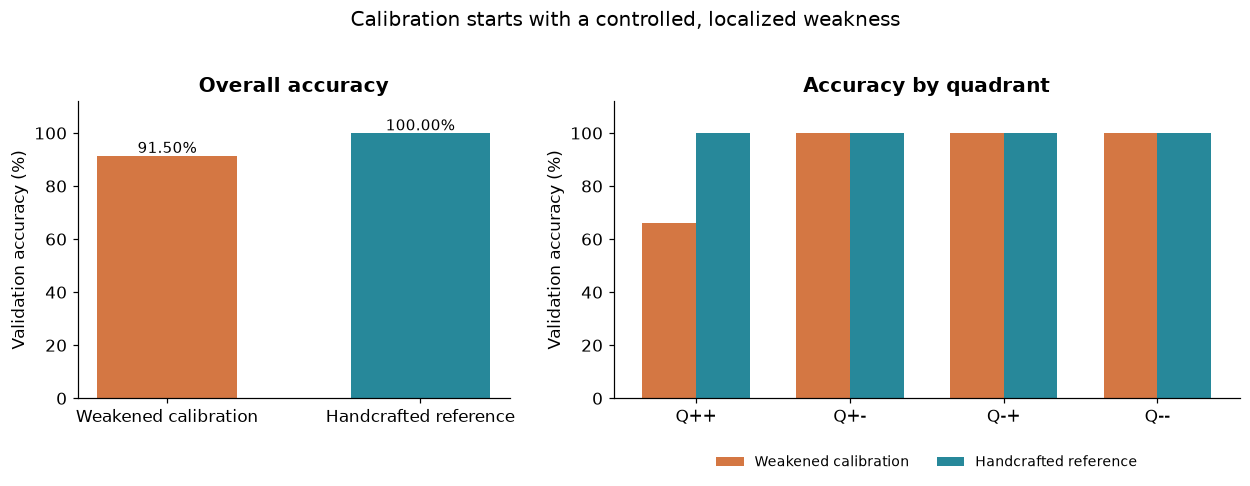

Weakened Q++ sample count: 256
These are validation diagnostics, not LLM or held-out outcomes.


In [2]:
labels=['Weakened calibration','Handcrafted reference']
colors=['#d47743','#27889a']
models=[weak_metrics,ref_metrics]
fig,axes=plt.subplots(1,2,figsize=(11.5,4.4),gridspec_kw={'width_ratios':[1,1.45]})
bars=axes[0].bar(labels,[m['accuracy']*100 for m in models],color=colors,width=.55)
for b in bars:
    axes[0].text(b.get_x()+b.get_width()/2,b.get_height()+1,f'{b.get_height():.2f}%',ha='center',fontsize=10)
axes[0].set(ylim=(0,112),ylabel='Validation accuracy (%)',title='Overall accuracy')
qnames=['Q++','Q+-','Q-+','Q--']; pos=np.arange(4); width=.35
for offset,m,label,color in zip((-.5,.5),models,labels,colors):
    vals=[m['quadrants'][q]['accuracy']*100 for q in qnames]
    axes[1].bar(pos+offset*width,vals,width,label=label,color=color)
axes[1].set(xticks=pos,xticklabels=qnames,ylim=(0,112),ylabel='Validation accuracy (%)',title='Accuracy by quadrant')
axes[1].legend(frameon=False,fontsize=9,loc='upper center',bbox_to_anchor=(.5,-.15),ncol=2)
fig.suptitle('Calibration starts with a controlled, localized weakness',y=1.02,fontsize=13)
fig.tight_layout(); save_figure(fig,'16_calibration_diagnostics'); plt.show()
print('Weakened Q++ sample count:', weak_metrics['quadrants']['Q++']['count'])
print('These are validation diagnostics, not LLM or held-out outcomes.')

## 2. What is prepared for the reviewers?

Two separate adaptive repair sessions were created for GPT-6.2 Astra and Qwen3.8-27B. The first calibration run is reported in notebook 6; the staged Qwen rerun is reported in notebook 7. Each is intended to use a fresh conversation. They receive matching model weights, the XNOR repair task, and a budget of four batches of eight chosen inputs.

The table below reads the local session records. A prepared prompt is not a reviewer response. The actual serving provider, deployment identity, version, settings, and any usage or cost must be recorded when a session is run.

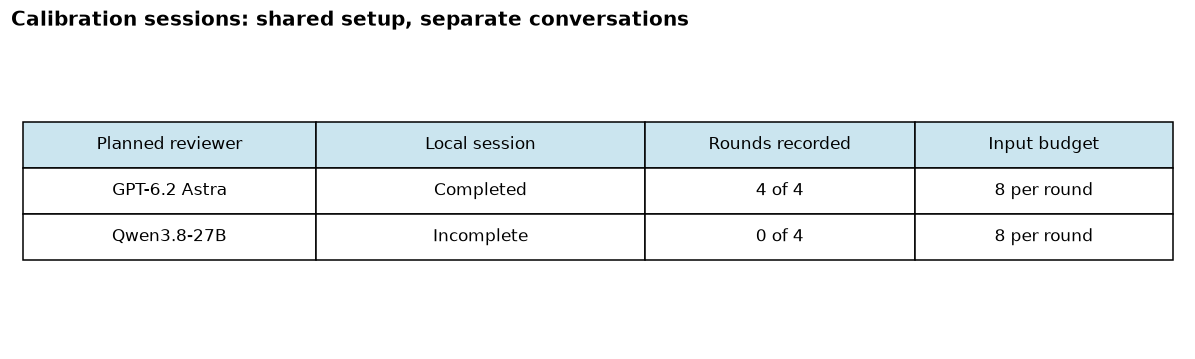

Same checkpoint and repair template hashes: True
Condition: adaptive probes; maximum inputs per reviewer: 32
Session counts reflect local transcripts, not proof of a completed or valid reviewer response.


In [3]:
session_specs=[('GPT-6.2 Astra','repair-calibration-astra'),('Qwen3.8-27B','repair-calibration-qwen')]
rows=[]
for label,sid in session_specs:
    meta_path=ROOT/'private'/'review_sessions'/sid/'session.json'
    probe_path=ROOT/'private'/'probe_sessions'/sid/'session.json'
    if not meta_path.is_file() or not probe_path.is_file():
        rows.append({'reviewer':label,'sid':sid,'available':False,'status':'Missing or changed','rounds':None,'checkpoint_hash':None,'template_hash':None})
        continue
    meta=json.loads(meta_path.read_text()); probe=json.loads(probe_path.read_text())
    checkpoint_path=meta_path.parent/'checkpoint.pt'
    prompt_path=ROOT/'packets'/f"{meta['packet_id']}.md"
    valid=(meta['task']=='repair' and meta['phase']=='calibration' and meta['condition']=='adaptive_probes'
           and digest(checkpoint_path)==meta['checkpoint_sha256'] and digest(prompt_path)==meta['prompt_sha256']
           and probe['checkpoint_sha256']==meta['checkpoint_sha256'])
    count=len(list((ROOT/'responses'/'probes'/sid).glob('round-*.json')))
    state='Completed' if (meta_path.parent/'repair_frozen.json').is_file() else ('Incomplete' if (meta_path.parent/'calibration_status.json').is_file() else 'Prepared')
    if not valid: state='Missing or changed'
    rows.append({'reviewer':label,'sid':sid,'available':valid,'status':state,'rounds':count,'checkpoint_hash':meta['checkpoint_sha256'],
                 'template_hash':meta['template_sha256']})
fig,ax=plt.subplots(figsize=(11,3.4)); ax.axis('off')
table_data=[[r['reviewer'],r['status'],
             f"{r['rounds']} of 4" if r['rounds'] is not None else 'Unavailable','8 per round'] for r in rows]
table=ax.table(cellText=table_data,colLabels=['Planned reviewer','Local session','Rounds recorded','Input budget'],
               cellLoc='center',loc='center',colColours=['#cbe5ef']*4,colWidths=[.25,.28,.23,.22])
table.auto_set_font_size(False); table.set_fontsize(11); table.scale(1,2.3)
ax.set_title('Calibration sessions: shared setup, separate conversations',loc='left',pad=5)
fig.tight_layout(); save_figure(fig,'17_calibration_sessions'); plt.show()
matched=all(r['available'] for r in rows) and rows[0]['checkpoint_hash']==rows[1]['checkpoint_hash'] and rows[0]['template_hash']==rows[1]['template_hash']
print('Same checkpoint and repair template hashes:',matched)
print('Condition: adaptive probes; maximum inputs per reviewer:',config['reviewer']['probe_rounds']*config['reviewer']['inputs_per_round'])
print('Session counts reflect local transcripts, not proof of a completed or valid reviewer response.')

## 3. What happens during calibration?

1. Send each reviewer only its rendered prompt, in a fresh conversation.
2. Relay up to four batches of eight reviewer-chosen inputs; return only the frozen model's input/logit pairs. Repeated inputs count.
3. Preserve the final response and freeze a validated edit proposal. Compare calibration candidates with their starting checkpoint on development validation data.
4. Record model/provider settings, incomplete sessions, response-format issues, and any prompt revisions **before** the main cohort is planned.

The prepared files and manual commands are listed in the local private operator checklist. The current exported repair prompt asks for **one scalar, row, or column multiplier between 0 and 2**. It does not authorize automatic API calls.

## 4. From calibration to main evaluation

The repair-study tooling supports the steps below, but the diagram is a **workflow**, not a claim that main collection or held-out scoring has occurred. A study plan fixes the intended reviewer, evidence condition, and checkpoint for each session before main export. The freeze records completed proposals, artifacts, and explicit missing or partial sessions.

After freezing, scoring checks the stored hashes and compares starting and edited accuracy on the same private final examples. It reports overall and quadrant results, not a significance test. The held-out set must not be used to iteratively tune edits.

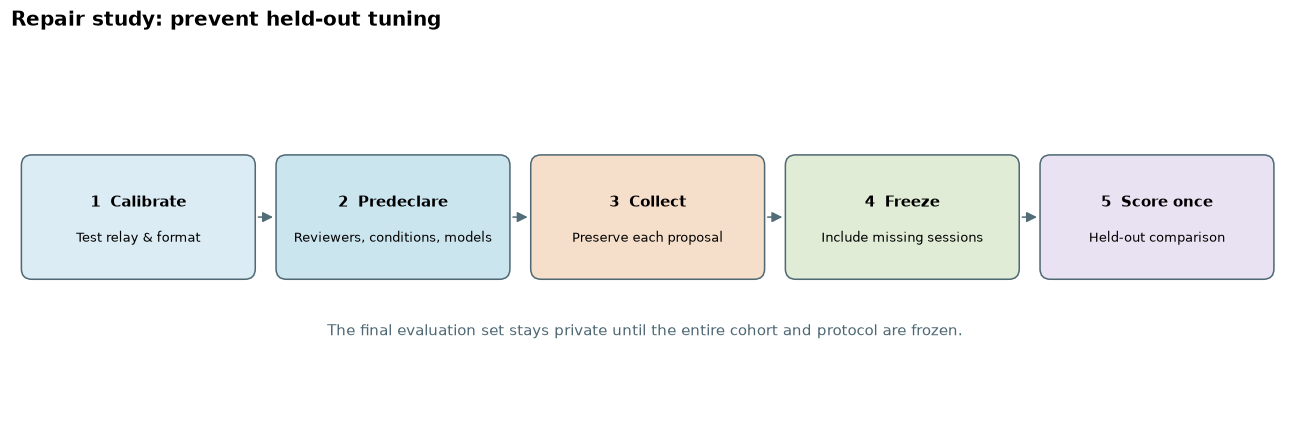

In [4]:
fig,ax=plt.subplots(figsize=(12,4)); ax.set(xlim=(-.1,12.25),ylim=(0,3.6)); ax.axis('off')
boxes=[(.10,'1  Calibrate','Test relay & format','#dcecf4'),
       (2.55,'2  Predeclare','Reviewers, conditions, models','#cbe5ef'),
       (5.00,'3  Collect','Preserve each proposal','#f6dfca'),
       (7.45,'4  Freeze','Include missing sessions','#e0ecd5'),
       (9.90,'5  Score once','Held-out comparison','#e9e2f2')]
for x,title,sub,color in boxes:
    ax.add_patch(FancyBboxPatch((x,1.4),2.05,1.0,boxstyle='round,pad=.1',facecolor=color,edgecolor='#4f6873'))
    ax.text(x+1.025,2.04,title,ha='center',va='center',weight='bold',fontsize=10)
    ax.text(x+1.025,1.7,sub,ha='center',va='center',fontsize=8.5)
for x in (2.25,4.70,7.15,9.60):
    ax.add_patch(FancyArrowPatch((x,1.9),(x+.20,1.9),arrowstyle='-|>',mutation_scale=14,color='#536d78'))
ax.text(6,.76,'The final evaluation set stays private until the entire cohort and protocol are frozen.',ha='center',fontsize=10,color='#4d6773')
ax.set_title('Repair study: prevent held-out tuning',loc='left',pad=10)
fig.tight_layout(); save_figure(fig,'18_repair_study_lifecycle'); plt.show()

## Current status and limitations

- Session records above reflect the current local calibration status. Notebook 6 reports the initial calibration, and notebook 7 reports the staged Qwen rerun; no final held-out result is represented here.
- The calibration fault was deliberately constructed and has a known inverse. A successful calibration repair would test the procedure; it would not establish general weight-reading ability.
- The repair task tells the reviewer the intended XNOR behavior. The separate ablation-prediction task keeps the target rule private and has its own evaluation still to implement.
- Paid reviewer collection requires explicit authorization. No LLM calls are made by this notebook.